# OFDM over Rayleigh fading: pilots, LS estimation and delay-domain filtering

A static-per-symbol (block-fading) multipath OFDM link, extended with **comb pilots, least-squares (LS) channel estimation and delay-domain noise filtering**.

**What changed compared with the previous version**
- **New:** pilot subcarriers + LS estimation + interpolation (Section 5) and the **delay-domain filter** (Section 6), compared against perfect CSI.
- **Faster:** mapper/demapper use lookup tables instead of Python loops (about 50x faster), the channel is applied to all OFDM symbols at once, and the pipeline is split into small functions so a full BER sweep takes a few seconds.
- **Cleaner conventions:** unitary FFTs (`norm="ortho"`), so **SNR = 1/sigma^2** exactly (unit-power symbols and channel) instead of measuring the received power. The RNG is seeded, so results are reproducible.

Run the cells top to bottom.

## 0. Imports

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

rng = np.random.default_rng(42)   # one seeded generator used everywhere -> reproducible runs


## 1. Simulation parameters

In [ ]:
N = 64                    # OFDM subcarriers (FFT size)
CP = 16                   # cyclic prefix length (samples)
num_symbols = 200         # OFDM symbols for the single-SNR run
snr_db = 20               # SNR for the single-SNR run
modulation_type = 'QPSK'  # 'QPSK' or '16QAM'

# Channel
L_taps = 4                # multipath taps
decay = 3.0               # tap power decay (higher = faster decay)

# Pilots + delay filter (new)
PILOT_SPACING = 4         # one comb pilot every PILOT_SPACING subcarriers
WIN_LEN = 8               # delay-domain window length (see Section 6)

# Design rules, checked up front
assert CP >= L_taps, "CP must cover the channel impulse response (no ISI)"
assert N // PILOT_SPACING > L_taps, "pilots must be dense enough to see a channel with L taps"
assert L_taps <= WIN_LEN <= min(CP, N // PILOT_SPACING), "need L <= WIN_LEN <= min(CP, N/PILOT_SPACING)"


## 2. Rayleigh fading multipath channel and noise
Each OFDM symbol gets its own independent channel (block fading). Everything is generated for all symbols at once, and the tap loop (only `L_taps` iterations) replaces the old loop over symbols.

With unitary FFTs and a long enough CP, the receiver sees $Y[k] = H[k]\,X[k] + W[k]$, where $H = \mathrm{DFT}(h)$ (unnormalised) and $W$ has variance $\sigma^2 = 1/\mathrm{SNR}$.

In [ ]:
tap_powers = np.exp(-np.arange(L_taps) / decay)
tap_powers /= tap_powers.sum()            # unit total channel power


def generate_channel(n_symbols):
    """Independent Rayleigh taps for every OFDM symbol, shape (n_symbols, L_taps)."""
    g = rng.standard_normal((n_symbols, L_taps)) + 1j * rng.standard_normal((n_symbols, L_taps))
    return g * np.sqrt(tap_powers / 2)


def freq_response(h):
    """True per-subcarrier channel H[k] = sum_l h_l e^{-j 2 pi k l / N}, shape (n_symbols, N)."""
    return np.fft.fft(h, n=N, axis=1)


def apply_channel(x, h):
    """Noise-free multipath convolution y[n] = sum_l h_l x[n-l], done for all symbols at once."""
    y = np.zeros_like(x)
    for l in range(L_taps):
        y[:, l:] += h[:, [l]] * x[:, :x.shape[1] - l]
    return y


def add_noise(y, snr_db):
    """Complex AWGN with variance 1/SNR (signal and channel have unit power)."""
    sigma2 = 10 ** (-snr_db / 10)
    noise = rng.standard_normal(y.shape) + 1j * rng.standard_normal(y.shape)
    return y + np.sqrt(sigma2 / 2) * noise


## 3. Constellation mapper and demapper
Gray-coded QPSK / 16-QAM with unit average power. The mapper is a table lookup (bits to table index with a dot product), and the demapper slices each axis with `digitize` / sign tests. The bit mapping is identical to the previous notebook.

In [ ]:
class Modem:
    """Gray-coded QPSK / 16-QAM, unit average power, fully vectorised."""

    def __init__(self, mod_type):
        if mod_type == 'QPSK':
            self.bps = 2
            lv = np.array([1.0, -1.0])               # bit 0 -> +1, bit 1 -> -1
            # index = 2*b0 + b1 : b0 drives the imaginary sign, b1 the real sign
            self.table = np.array([lv[i & 1] + 1j * lv[i >> 1] for i in range(4)]) / np.sqrt(2)
        elif mod_type == '16QAM':
            self.bps = 4
            lv = np.array([-3.0, -1.0, 3.0, 1.0])    # Gray: 00->-3, 01->-1, 11->+1, 10->+3
            self.table = np.array([lv[i >> 2] + 1j * lv[i & 3] for i in range(16)]) / np.sqrt(10)
        else:
            raise NotImplementedError(f"Unknown modulation type: {mod_type}")
        self.mod_type = mod_type
        self.weights = 2 ** np.arange(self.bps - 1, -1, -1)

    def mod(self, bits):
        """bits (any shape, multiple of bps) -> flat array of symbols."""
        return self.table[np.asarray(bits).reshape(-1, self.bps) @ self.weights]

    def demod(self, sym):
        """symbols -> flat array of hard-decision bits (minimum-distance detection)."""
        sym = np.asarray(sym).ravel()
        if self.bps == 2:
            return np.column_stack([sym.imag < 0, sym.real < 0]).astype(np.int8).ravel()
        s = sym * np.sqrt(10)
        gray = np.array([0b00, 0b01, 0b11, 0b10])    # PAM level index (-3,-1,1,3) -> Gray bits
        gi = gray[np.digitize(s.real, [-2, 0, 2])]
        gq = gray[np.digitize(s.imag, [-2, 0, 2])]
        return np.column_stack([gi >> 1, gi & 1, gq >> 1, gq & 1]).astype(np.int8).ravel()


modem = Modem(modulation_type)

# self-test: noiseless round trip must be error-free, symbols must have unit power
_b = rng.integers(0, 2, 4000 * modem.bps)
assert np.array_equal(modem.demod(modem.mod(_b)), _b)
print(f"{modulation_type}: round trip OK, mean symbol power = {np.mean(np.abs(modem.table)**2):.3f}")


QPSK: round trip OK, mean symbol power = 1.000


## 4. OFDM chain, pilot layout and a perfect-CSI baseline
Every OFDM symbol carries **comb pilots** (known symbols, every `PILOT_SPACING` subcarriers, plus the last subcarrier so interpolation never has to extrapolate); all other subcarriers carry data. BER is counted on data subcarriers only.

`make_link` builds bits, frames, the transmitted signal and the noise-free channel output once; `receive` then adds noise for any SNR, so a sweep reuses the same channel realizations.

In [ ]:
PILOT_IDX = np.unique(np.r_[np.arange(0, N, PILOT_SPACING), N - 1])
DATA_IDX = np.setdiff1d(np.arange(N), PILOT_IDX)
PILOT_VAL = (1 + 1j) / np.sqrt(2)         # known pilot symbol (unit power)
SUBCARRIERS = np.arange(N)


def ofdm_tx(X):
    """Frequency-domain symbols (n_symbols, N) -> IFFT -> prepend cyclic prefix."""
    x = np.fft.ifft(X, axis=1, norm="ortho")
    return np.hstack([x[:, -CP:], x])


def ofdm_rx(y):
    """Remove cyclic prefix -> FFT."""
    return np.fft.fft(y[:, CP:CP + N], axis=1, norm="ortho")


def make_link(n_symbols):
    """Random bits -> data+pilot frames -> OFDM -> channel (noise-free)."""
    bits = rng.integers(0, 2, (n_symbols, len(DATA_IDX) * modem.bps))
    X = np.zeros((n_symbols, N), dtype=complex)
    X[:, DATA_IDX] = modem.mod(bits).reshape(n_symbols, -1)
    X[:, PILOT_IDX] = PILOT_VAL
    h = generate_channel(n_symbols)
    return dict(bits=bits, X=X, h=h, H=freq_response(h), y_clean=apply_channel(ofdm_tx(X), h))


def receive(link, snr_db):
    """Add noise at the given SNR, then CP removal + FFT -> Y (n_symbols, N)."""
    return ofdm_rx(add_noise(link['y_clean'], snr_db))


def zf_ber(Y, H_est, bits):
    """1-tap zero-forcing equalizer on the data subcarriers, then hard-decision BER."""
    X_hat = Y[:, DATA_IDX] / H_est[:, DATA_IDX]
    return np.mean(modem.demod(X_hat) != np.asarray(bits).ravel())


# --- baseline: ideal ZF with perfect CSI ---
link = make_link(num_symbols)
Y = receive(link, snr_db)
ber_perfect = zf_ber(Y, link['H'], link['bits'])
n_bits = link['bits'].size
print(f"Modulation: {modulation_type}, SNR = {snr_db} dB, {num_symbols} OFDM symbols")
print(f"Pilots per symbol: {len(PILOT_IDX)}, data subcarriers: {len(DATA_IDX)}")
print(f"Perfect-CSI ZF: {int(round(ber_perfect * n_bits))} errors in {n_bits} bits, BER = {ber_perfect:.6f}")


Modulation: QPSK, SNR = 20 dB, 200 OFDM symbols
Pilots per symbol: 17, data subcarriers: 47
Perfect-CSI ZF: 102 errors in 18800 bits, BER = 0.005426


## 5. Pilot-based LS channel estimation
At a pilot, $Y[k_p] = H[k_p]\,X_p + W[k_p]$, so the **LS estimate** is $\hat H[k_p] = Y[k_p]/X_p = H[k_p] + W[k_p]/X_p$: the true channel plus noise. The estimates at the pilots are then **interpolated** (linear or cubic spline) to every subcarrier. This gives a usable estimate, but it is noisy, and the noise is exactly what the next section removes.

In [ ]:
def ls_estimate(Y, kind='linear'):
    """LS at the pilots (Y_p / X_p), interpolated over frequency to all N subcarriers."""
    H_pilot = Y[:, PILOT_IDX] / PILOT_VAL
    return interp1d(PILOT_IDX, H_pilot, kind=kind, axis=1)(SUBCARRIERS)


## 6. Delay-domain filtering

### The idea
The channel has only $L$ taps in time, so its frequency response
$$H[k]=\sum_{l=0}^{L-1} h_l\,e^{-j2\pi kl/N}$$
is very smooth across subcarriers: $N$ numbers fully described by $L$ values. The LS error, however, is essentially random from subcarrier to subcarrier. Look at both in the **delay domain** (the IDFT of the frequency response):

- the **signal** lives only in delay bins $0,\dots,L-1$;
- the **noise** is spread over many bins.

So we can throw away every delay bin that can't contain channel energy:

1. $\hat h = \mathrm{IDFT}(\hat H_{LS})$: move the LS estimate to the delay domain.
2. **Window:** keep bins $0,\dots,W-1$ and set the rest to zero.
3. $\hat H_{clean} = \mathrm{DFT}(\hat h_{windowed})$: back to the frequency domain.

### Why it helps
All the channel energy survives, while the noise energy in the discarded bins disappears. For white noise on all $N$ bins the noise power drops by $W/N$. With comb pilots plus interpolation, the interpolated noise is already concentrated in the first $N/P$ delay bins (P = pilot spacing), so the realistic gain is roughly $W/(N/P)$. Measured here: about 0.5 for $W=8$.

Equivalently, the filter is a **circular convolution along frequency with a sinc-like (Dirichlet) kernel**, so each subcarrier's estimate becomes a weighted average of its neighbours. That is exactly "smoothing the noise".

### Choosing the window length $W$
- $W \ge L$: a shorter window cuts off real channel taps and the estimate gets *worse*.
- $W \le \mathrm{CP}$: the system guarantees the channel fits inside the CP, so bins beyond it can only be noise.
- $W \le N/P$: beyond that you keep aliases created by the interpolation.
- In practice choose a little above $L$ as a margin (e.g. for fractional-sample delays that leak into neighbouring bins).

### Limits
The filter assumes the channel is constant over the OFDM symbol (block fading, as here) and that the taps sit in the first $W$ samples. With strong Doppler the frequency response is no longer a simple $L$-tap response, which needs a different approach (e.g. a BEM).

In [ ]:
def delay_filter(H_ls, win_len=WIN_LEN):
    """IDFT -> keep the first win_len delay bins -> DFT.   Works on (n_symbols, N) arrays."""
    h = np.fft.ifft(H_ls, axis=1)
    h[:, win_len:] = 0
    return np.fft.fft(h, axis=1)


def delay_filter_kernel(win_len=WIN_LEN):
    """The same filter seen along frequency: H_clean = circular convolution of H_ls with this kernel."""
    d = (np.arange(N) < win_len).astype(float)
    return np.fft.fft(d) / N


kernel = delay_filter_kernel()
print(f"kernel weights sum to {kernel.sum().real:.3f} (flat channels pass unchanged)")
print(f"noise gain for white noise = sum|kernel|^2 = {np.sum(np.abs(kernel)**2):.3f}  (= WIN_LEN/N = {WIN_LEN / N:.3f})")

# sanity check: smoothing along frequency with the kernel == the delay-domain filter
H_test = ls_estimate(receive(link, 10))[0]
idx = (SUBCARRIERS[:, None] - SUBCARRIERS[None, :]) % N                # (k - m) mod N
via_kernel = (H_test[idx] * kernel[None, :]).sum(axis=1)
assert np.allclose(via_kernel, delay_filter(H_test[None, :])[0])
print("kernel view and delay-domain view give identical results")


kernel weights sum to 1.000 (flat channels pass unchanged)
noise gain for white noise = sum|kernel|^2 = 0.125  (= WIN_LEN/N = 0.125)
kernel view and delay-domain view give identical results


### How it looks on one OFDM symbol (SNR = 10 dB)
Left: the LS estimate in the delay domain. The true taps (red) sit in the first few bins, everything else is noise or interpolation residue, and the shaded window is what survives. Right: the frequency response before and after filtering.

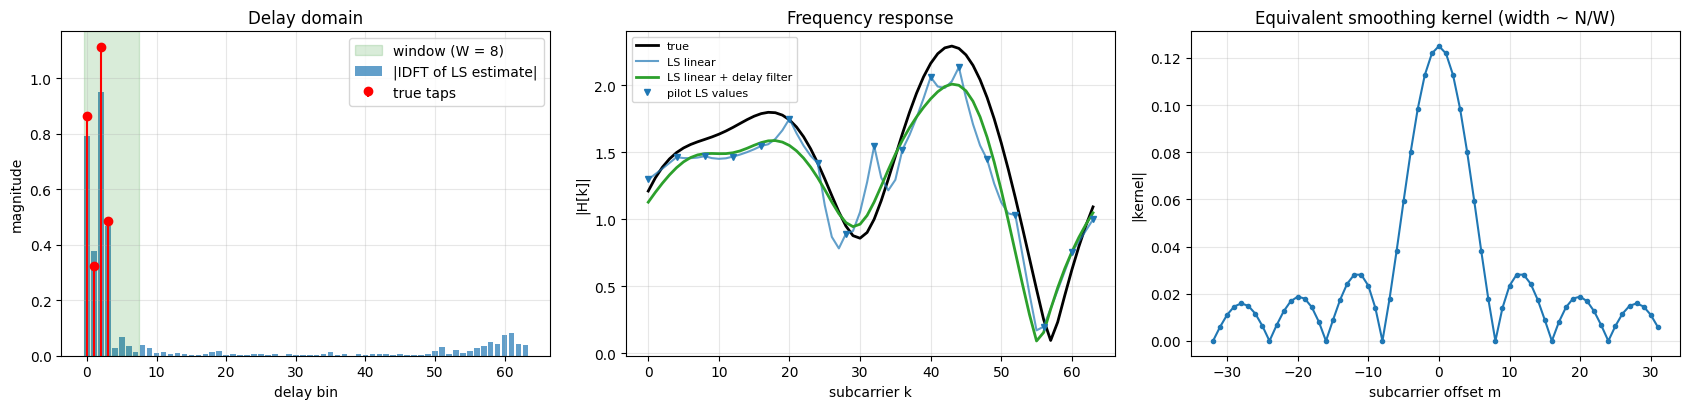

In [ ]:
demo_snr = 10
Yd = receive(link, demo_snr)
H_ls = ls_estimate(Yd, 'linear')
H_flt = delay_filter(H_ls)
h_ls = np.fft.ifft(H_ls, axis=1)[0]
h_true = link['h'][0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

ax[0].bar(SUBCARRIERS, np.abs(h_ls), color='tab:blue', alpha=0.7, label='|IDFT of LS estimate|')
ax[0].stem(np.arange(L_taps), np.abs(h_true), linefmt='r-', markerfmt='ro', basefmt=' ', label='true taps')
ax[0].axvspan(-0.5, WIN_LEN - 0.5, color='green', alpha=0.15, label=f'window (W = {WIN_LEN})')
ax[0].set(xlabel='delay bin', ylabel='magnitude', title='Delay domain')
ax[0].legend()

ax[1].plot(SUBCARRIERS, np.abs(link['H'][0]), 'k', lw=2, label='true')
ax[1].plot(SUBCARRIERS, np.abs(H_ls[0]), color='tab:blue', alpha=0.7, label='LS linear')
ax[1].plot(SUBCARRIERS, np.abs(H_flt[0]), color='tab:green', lw=2, label='LS linear + delay filter')
ax[1].plot(PILOT_IDX, np.abs(Yd[0, PILOT_IDX] / PILOT_VAL), 'v', color='tab:blue', ms=5, label='pilot LS values')
ax[1].set(xlabel='subcarrier k', ylabel='|H[k]|', title='Frequency response'); ax[1].legend(fontsize=8)

ax[2].plot(np.arange(N) - N // 2, np.abs(np.fft.fftshift(kernel)), 'o-', ms=3)
ax[2].set(xlabel='subcarrier offset m', ylabel='|kernel|', title='Equivalent smoothing kernel (width ~ N/W)')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 7. Comparison at a single SNR
Perfect CSI, LS (linear / cubic spline) and the same two estimators followed by the delay filter. `MSE` is the channel-estimation error over all subcarriers.

QPSK, SNR = 20 dB, W = 8
estimator                         BER   channel MSE
Perfect CSI                   0.00543      0.00e+00
LS linear                     0.01059      9.78e-03
LS spline                     0.01027      9.11e-03
LS linear + delay filt        0.00856      5.56e-03
LS spline + delay filt        0.00809      4.69e-03


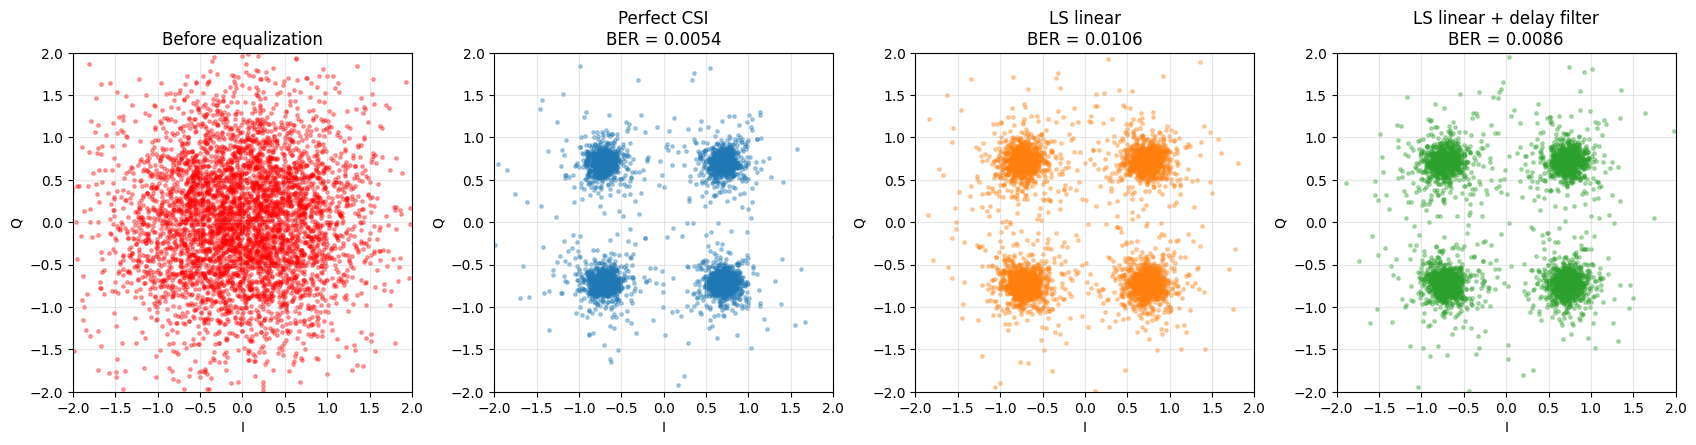

In [ ]:
names = ["Perfect CSI", "LS linear", "LS spline", "LS linear + delay filt", "LS spline + delay filt"]


def all_estimates(Y, H_true, win_len=WIN_LEN):
    Hl, Hs = ls_estimate(Y, 'linear'), ls_estimate(Y, 'cubic')
    return [H_true, Hl, Hs, delay_filter(Hl, win_len), delay_filter(Hs, win_len)]


Y = receive(link, snr_db)
ests = all_estimates(Y, link['H'])
bers = [zf_ber(Y, He, link['bits']) for He in ests]
mses = [np.mean(np.abs(He - link['H']) ** 2) for He in ests]

print(f"{modulation_type}, SNR = {snr_db} dB, W = {WIN_LEN}")
print(f"{'estimator':26s} {'BER':>10s} {'channel MSE':>13s}")
for n_, b, m_ in zip(names, bers, mses):
    print(f"{n_:26s} {b:10.5f} {m_:13.2e}")

# constellations after equalization (first 100 symbols, outliers from deep fades are clipped to +/-2)
show = slice(0, 100)
panels = [("Before equalization", Y[show][:, DATA_IDX], 'red', None),
          ("Perfect CSI", Y[show][:, DATA_IDX] / ests[0][show][:, DATA_IDX], 'tab:blue', bers[0]),
          ("LS linear", Y[show][:, DATA_IDX] / ests[1][show][:, DATA_IDX], 'tab:orange', bers[1]),
          ("LS linear + delay filter", Y[show][:, DATA_IDX] / ests[3][show][:, DATA_IDX], 'tab:green', bers[3])]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3))
for a, (title, pts, c, b) in zip(ax, panels):
    a.scatter(pts.real.ravel(), pts.imag.ravel(), s=6, alpha=0.35, color=c)
    a.set(xlim=(-2, 2), ylim=(-2, 2), xlabel='I', ylabel='Q', aspect='equal',
          title=title if b is None else f"{title}\nBER = {b:.4f}")
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 8. BER and channel MSE versus SNR
The same channel realizations are reused at every SNR; only the noise is redrawn.

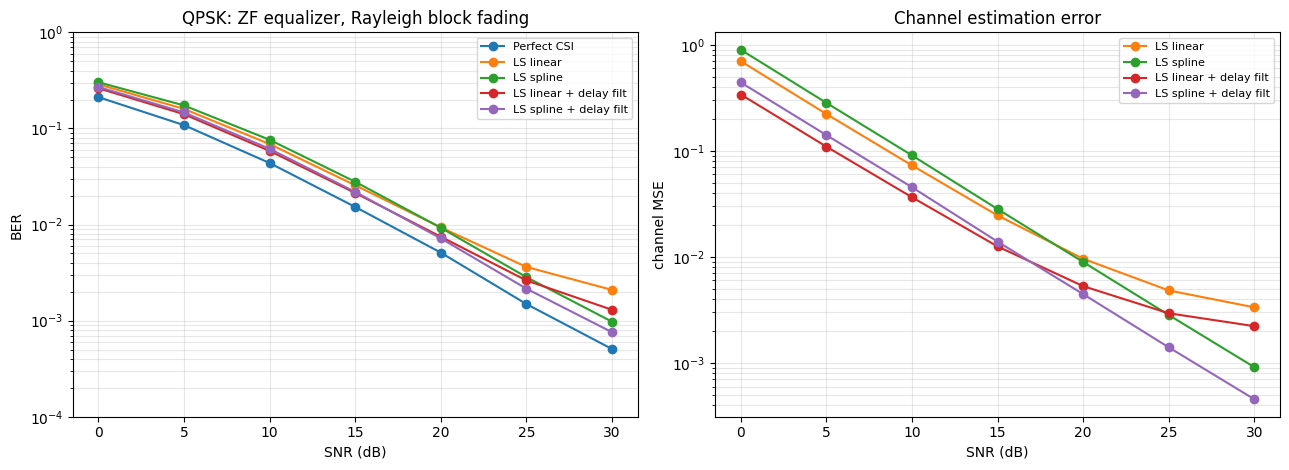

In [ ]:
snrs = np.arange(0, 31, 5)
link_s = make_link(3000)
ber_s = np.zeros((len(names), len(snrs)))
mse_s = np.zeros((len(names), len(snrs)))
for si, s in enumerate(snrs):
    Ys = receive(link_s, s)
    for ei, He in enumerate(all_estimates(Ys, link_s['H'])):
        ber_s[ei, si] = zf_ber(Ys, He, link_s['bits'])
        mse_s[ei, si] = np.mean(np.abs(He - link_s['H']) ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for ei, (n_, b) in enumerate(zip(names, ber_s)):
    ax[0].semilogy(snrs, np.maximum(b, 1e-6), marker='o', color=f'C{ei}', label=n_)
ax[0].set(xlabel='SNR (dB)', ylabel='BER', title=f'{modulation_type}: ZF equalizer, Rayleigh block fading', ylim=(1e-4, 1))
for ei, (n_, m_) in enumerate(zip(names[1:], mse_s[1:]), start=1):
    ax[1].semilogy(snrs, m_, marker='o', color=f'C{ei}', label=n_)
ax[1].set(xlabel='SNR (dB)', ylabel='channel MSE', title='Channel estimation error')
for a in ax:
    a.legend(fontsize=8); a.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()


**Reading the plots.** For each interpolation method, adding the delay filter lowers the channel MSE at every SNR (compare linear vs linear + filter, and spline vs spline + filter). At low and medium SNR the LS *noise* dominates, which is what the filter removes. At high SNR the *interpolation* error takes over; it is much larger for linear interpolation than for the cubic spline, so the linear curves flatten out while the spline ones keep improving, and the filter cannot fix interpolation error. Perfect CSI is the lower bound: even then ZF still suffers from noise enhancement on faded subcarriers.

## 9. Choosing the window length
Channel MSE of *LS linear + delay filter* as the window grows, with the unfiltered LS error as dashed lines. Too short a window (below the number of taps) cuts the channel itself and is worse than not filtering; beyond $L$ it is a small, gradual cost.

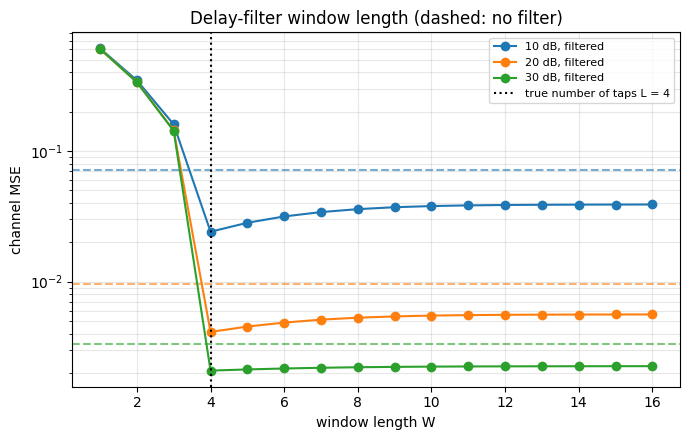

In [ ]:
Ws = np.arange(1, min(CP, N // PILOT_SPACING) + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, s in enumerate([10, 20, 30]):
    Yw = receive(link_s, s)
    Hl = ls_estimate(Yw, 'linear')
    mse_w = [np.mean(np.abs(delay_filter(Hl, W) - link_s['H']) ** 2) for W in Ws]
    ax.semilogy(Ws, mse_w, marker='o', color=f'C{i}', label=f'{s} dB, filtered')
    ax.axhline(np.mean(np.abs(Hl - link_s['H']) ** 2), color=f'C{i}', ls='--', alpha=0.6)
ax.axvline(L_taps, color='k', ls=':', label=f'true number of taps L = {L_taps}')
ax.set(xlabel='window length W', ylabel='channel MSE', title='Delay-filter window length (dashed: no filter)')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()


## Notes
- To try 16-QAM, set `modulation_type = '16QAM'` in Section 1 and rerun from the top; the BER curves shift up but the ranking of the estimators stays the same.
- `PILOT_SPACING` trades overhead against estimation quality: more pilots means less data throughput but a better estimate, and the delay filter helps most when pilots are dense enough to see the channel ($N/P > L$).
- `WIN_LEN` should be a little larger than the true channel length, as Section 9 shows.

---
# End-to-end audio demo and Doppler extension

All original cells above, including their comments, text blocks, simulation parameters and delay filter, are preserved unchanged. The following cells add the audio and mobile-channel functionality from `OFDM_audio_demo (3).ipynb`.

Run from the top. Requirements: `numpy`, `scipy`, `matplotlib`, `ipython` and a Jupyter Python kernel. Set `WAV_PATH` below to use your own WAV file; otherwise the demo generates a synthetic clip. Recovered WAV files are written to `audio_out` relative to the notebook's working directory.

The static audio demo uses the original Rayleigh block-fading channel, pilot layout and delay filter. A separate payload-link function leaves the original random-bit `make_link(n_symbols)` interface intact. The optional Doppler extension adds time-varying taps, BEM estimation and banded MMSE. Its pilot cluster count is chosen to fit the original FFT size.

The original explanatory text above is retained verbatim. For clarity: in the implemented exponential tap-power formula, a larger `decay` produces slower power decay. Also, mu-law compresses dynamic range but does not guarantee that bit errors produce less audible clicks. Comparisons across receiver schemes share a channel and noise realization within each transmission; separate sweep points redraw the channel.

In [ ]:
import os
from scipy.io import wavfile
from scipy.signal import resample_poly
from IPython.display import Audio, display

BITS_PER_OFDM = len(DATA_IDX) * modem.bps


def make_audio_link(bits):
    """Payload bits -> padding -> original OFDM and Rayleigh channel."""
    bits = np.asarray(bits, dtype=np.int8).ravel()
    if bits.size == 0:
        raise ValueError("The audio payload must contain at least one bit.")
    n_symbols = (bits.size + BITS_PER_OFDM - 1) // BITS_PER_OFDM
    padded = np.zeros(n_symbols * BITS_PER_OFDM, dtype=np.int8)
    padded[:bits.size] = bits
    X = np.zeros((n_symbols, N), dtype=complex)
    X[:, DATA_IDX] = modem.mod(padded).reshape(n_symbols, -1)
    X[:, PILOT_IDX] = PILOT_VAL
    h = generate_channel(n_symbols)
    return dict(bits=padded, n_payload=bits.size, X=X, h=h, H=freq_response(h),
                y_clean=apply_channel(ofdm_tx(X), h))


def audio_snr_db(reference, recovered):
    """Waveform SNR relative to the original samples, including mu-law distortion."""
    reference = np.asarray(reference, dtype=float)
    recovered = np.asarray(recovered, dtype=float)
    if reference.shape != recovered.shape:
        raise ValueError("Reference and recovered audio must have the same shape.")
    signal = np.sum(reference ** 2)
    error = np.sum((reference - recovered) ** 2)
    if error == 0:
        return np.inf
    return 10 * np.log10(max(signal, np.finfo(float).tiny) / error)


---
# Audio layer

## 10. Audio front end: wav → mono → 8 kHz → mu-law 8-bit → bits

* Put your clip at `WAV_PATH`. If no file is found, a short synthetic test clip is generated so the notebook still runs end to end.
* Clip length is capped (`MAX_SECONDS`) so the bit count stays small. 3 s × 8 kHz × 8 bit = 192 kbit (the OFDM symbol count depends on the pilot layout), which runs in seconds because the pipeline is vectorised.
* **mu-law** companding is used because a flipped MSB in plain linear PCM makes a huge click; in mu-law the large-amplitude errors are better behaved perceptually and the SNR is more uniform across loudness.

In [ ]:
WAV_PATH = "input.wav"      # <- put your own clip here (any sample rate, mono or stereo)
OUT_DIR = "audio_out"
FS = 8000                   # target sample rate
MAX_SECONDS = 3
MU = 255
os.makedirs(OUT_DIR, exist_ok=True)


def synth_clip(fs=FS, seconds=MAX_SECONDS):
    """Fallback test signal: a gliding tone plus a few harmonics, with an amplitude envelope."""
    t = np.arange(int(fs * seconds)) / fs
    f0 = 220 + 180 * np.sin(2 * np.pi * 0.5 * t)
    ph = 2 * np.pi * np.cumsum(f0) / fs
    x = sum(a * np.sin(k * ph) for k, a in [(1, 1.0), (2, 0.5), (3, 0.3)])
    return 0.8 * x / np.max(np.abs(x)) * (0.6 + 0.4 * np.sin(2 * np.pi * 2 * t))


def load_audio(path):
    if not os.path.exists(path):
        print(f"'{path}' not found -> using synthetic test clip")
        return synth_clip()
    fs_in, raw = wavfile.read(path)
    x = raw.astype(np.float64)
    if np.issubdtype(raw.dtype, np.integer):
        x = (x - 128) / 128 if raw.dtype == np.uint8 else x / np.iinfo(raw.dtype).max
    if x.ndim > 1:
        x = x.mean(axis=1)                                   # mono
    g = np.gcd(int(fs_in), FS)
    x = resample_poly(x, FS // g, int(fs_in) // g)           # -> 8 kHz
    x = x[:FS * MAX_SECONDS]
    if x.size == 0:
        raise ValueError("The input WAV contains no audio samples.")
    return 0.95 * x / (np.max(np.abs(x)) + 1e-12)


def mulaw_encode(x):
    """float [-1,1] -> uint8 (offset binary)."""
    y = np.sign(x) * np.log1p(MU * np.abs(x)) / np.log1p(MU)
    return np.round((y + 1) / 2 * 255).astype(np.uint8)


def mulaw_decode(q):
    y = q.astype(np.float64) / 255 * 2 - 1
    return np.sign(y) * ((1 + MU) ** np.abs(y) - 1) / MU


def audio_to_bits(x):
    return np.unpackbits(mulaw_encode(x)).astype(np.int8)    # MSB first


def bits_to_audio(bits):
    n = (bits.size // 8) * 8
    return mulaw_decode(np.packbits(bits[:n].astype(np.uint8)))


audio = load_audio(WAV_PATH)
audio_bits = audio_to_bits(audio)
audio_ref = bits_to_audio(audio_bits)          # what a perfect (error-free) link would deliver

print(f"samples: {audio.size}  ({audio.size / FS:.1f} s @ {FS} Hz)")
print(f"payload bits: {audio_bits.size}  ->  {int(np.ceil(audio_bits.size / BITS_PER_OFDM))} OFDM symbols "
      f"({BITS_PER_OFDM} payload bits per symbol)")
wavfile.write(f"{OUT_DIR}/0_original.wav", FS, (audio * 32767).astype(np.int16))
wavfile.write(f"{OUT_DIR}/1_error_free_mulaw.wav", FS, (audio_ref * 32767).astype(np.int16))

'input.wav' not found -> using synthetic test clip
samples: 24000  (3.0 s @ 8000 Hz)
payload bits: 192000  ->  2043 OFDM symbols (94 payload bits per symbol)


## 11. Optional correction layer: Hamming(7,4) + interleaver

Hamming(7,4) corrects any single bit error per 7-bit codeword (rate 4/7, so it costs ~1.75× more OFDM symbols). Fading errors are bursty (they hit the faded subcarriers), so a random interleaver spreads each codeword across many OFDM symbols. Toggle with `USE_FEC`.

In [ ]:
P = np.array([[1, 1, 0], [1, 0, 1], [0, 1, 1], [1, 1, 1]])
G = np.hstack([np.eye(4, dtype=int), P])            # 4x7 generator  [I | P]
Hc = np.hstack([P.T, np.eye(3, dtype=int)])         # 3x7 parity-check [P^T | I]
SYNDROME_TO_POS = {int("".join(map(str, Hc[:, j])), 2): j for j in range(7)}


def hamming_encode(bits):
    return ((bits.reshape(-1, 4) @ G) % 2).astype(np.int8).ravel()


def hamming_decode(bits):
    r = bits.reshape(-1, 7).astype(int).copy()
    syn = (r @ Hc.T) % 2
    code_ = syn[:, 0] * 4 + syn[:, 1] * 2 + syn[:, 2]
    for s, pos in SYNDROME_TO_POS.items():
        r[code_ == s, pos] ^= 1                      # flip the single bit the syndrome points to
    return r[:, :4].astype(np.int8).ravel()


def make_interleaver(n, seed=7):
    return np.random.default_rng(seed).permutation(n)


# self-test: one error per codeword is always corrected
_d = rng.integers(0, 2, 4000).astype(np.int8)
_c = hamming_encode(_d).reshape(-1, 7)
_c[np.arange(_c.shape[0]), rng.integers(0, 7, _c.shape[0])] ^= 1
assert np.array_equal(hamming_decode(_c.ravel()), _d)
print("Hamming(7,4): single-error correction verified")

Hamming(7,4): single-error correction verified


## 12. Receiver schemes

All schemes see **the same received signal** `Y` (same channel, same noise), so the comparison is fair.

| Scheme | Channel estimate | Equalizer |
|---|---|---|
| No equalization | none | none |
| Comb-Linear + ZF | LS + linear interpolation | ZF |
| DFT-denoised + MMSE | LS + linear interp + delay filter | MMSE |
| DFT-denoised (spline) + MMSE | LS + cubic spline + delay filter | MMSE |
| Ideal CSI | true H | ZF |

In [ ]:
def equalize(Y, H_est, snr_db, kind):
    Yd, Hd = Y[:, DATA_IDX], H_est[:, DATA_IDX]
    if kind == 'ZF':
        return Yd / Hd
    if kind == 'MMSE':
        return np.conj(Hd) * Yd / (np.abs(Hd) ** 2 + 10 ** (-snr_db / 10))
    return Yd                                              # no equalization


SCHEMES = {
    "No equalization":              lambda Y, link, s: Y[:, DATA_IDX],
    "Comb-Linear + ZF":             lambda Y, link, s: equalize(Y, ls_estimate(Y, 'linear'), s, 'ZF'),
    "DFT-denoised + MMSE":          lambda Y, link, s: equalize(Y, delay_filter(ls_estimate(Y, 'linear')), s, 'MMSE'),
    "DFT-denoised spline + MMSE":   lambda Y, link, s: equalize(Y, delay_filter(ls_estimate(Y, 'cubic')), s, 'MMSE'),
    "Ideal CSI + ZF":               lambda Y, link, s: equalize(Y, link['H'], s, 'ZF'),
}


def transmit_audio(bits, snr_db, use_fec=False):
    """Run payload bits through the link once and decode them with every scheme.
    Returns {scheme: (rx_payload_bits, ber_on_payload)}."""
    tx = bits
    if use_fec:
        coded = hamming_encode(bits)
        perm = make_interleaver(coded.size)
        tx = coded[perm]
    link = make_audio_link(tx)
    Y = receive(link, snr_db)
    out = {}
    for name, fn in SCHEMES.items():
        rx = modem.demod(fn(Y, link, snr_db))[:link['n_payload']]
        if use_fec:
            deint = np.empty_like(rx)
            deint[perm] = rx
            rx = hamming_decode(deint)
        out[name] = (rx, np.mean(rx != bits))
    return out

## 13. Run the static Rayleigh audio demo

This first listening comparison uses the original block-fading channel and delay-domain filter. All receivers see the same received signal. Set `USE_FEC` to enable Hamming protection and interleaving.

In [ ]:
DEMO_SNR = 20
USE_FEC = False

res = transmit_audio(audio_bits, DEMO_SNR, USE_FEC)
decoded = {}
print(f"{modulation_type}, static Rayleigh, SNR={DEMO_SNR} dB, FEC={USE_FEC}")
print(f"{'scheme':48s} {'BER':>9s} {'audio SNR (dB)':>15s}")
for i, (name, (rx_bits, ber)) in enumerate(res.items(), start=2):
    y = bits_to_audio(rx_bits)
    decoded[name] = y
    print(f"{name:48s} {ber:9.5f} {audio_snr_db(audio, y):15.1f}")
    filename = ''.join(c if c.isalnum() else '_' for c in name)
    wavfile.write(f"{OUT_DIR}/static_{i}_{filename}.wav", FS,
                  (np.clip(y, -1, 1) * 32767).astype(np.int16))


QPSK, static Rayleigh, SNR=20 dB, FEC=False
scheme                                                 BER  audio SNR (dB)
No equalization                                    0.50908            -2.4
Comb-Linear + ZF                                   0.00946            13.5
DFT-denoised + MMSE                                0.00733            14.6
DFT-denoised spline + MMSE                         0.00717            14.8
Ideal CSI + ZF                                     0.00492            16.4


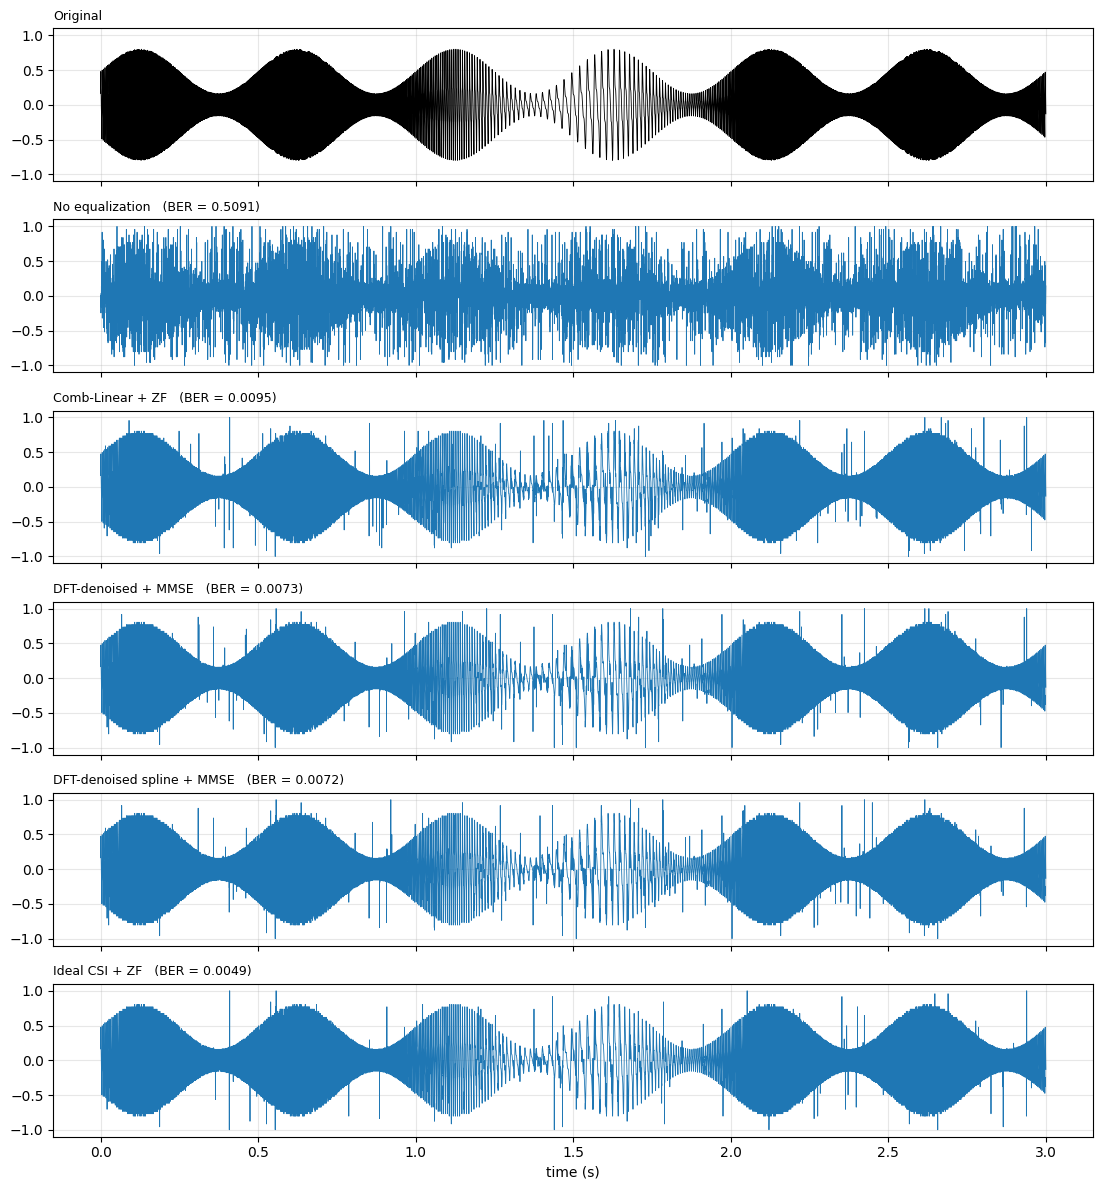

In [ ]:
fig, ax = plt.subplots(len(decoded) + 1, 1, figsize=(11, 2 * (len(decoded) + 1)), sharex=True, sharey=True)
t = np.arange(audio.size) / FS
ax[0].plot(t, audio, color='k', lw=0.6); ax[0].set_title("Original", fontsize=9, loc='left')
for a, (name, y) in zip(ax[1:], decoded.items()):
    a.plot(t[:y.size], y, lw=0.6); a.set_title(f"{name}   (BER = {res[name][1]:.4f})", fontsize=9, loc='left')
for a in ax: a.grid(alpha=0.3)
ax[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

In [ ]:
print("Original");                      display(Audio(audio, rate=FS))
print("Error-free mu-law (best possible with 8-bit)"); display(Audio(audio_ref, rate=FS))
for name, y in decoded.items():
    print(name);                       display(Audio(np.clip(y, -1, 1), rate=FS))

Original


Error-free mu-law (best possible with 8-bit)


No equalization


Comb-Linear + ZF


DFT-denoised + MMSE


DFT-denoised spline + MMSE


Ideal CSI + ZF


## 14. Audio quality vs SNR, with and without Hamming

Same idea as your BER plot, but on the audio: the more the estimator helps, the earlier the audio becomes clean.

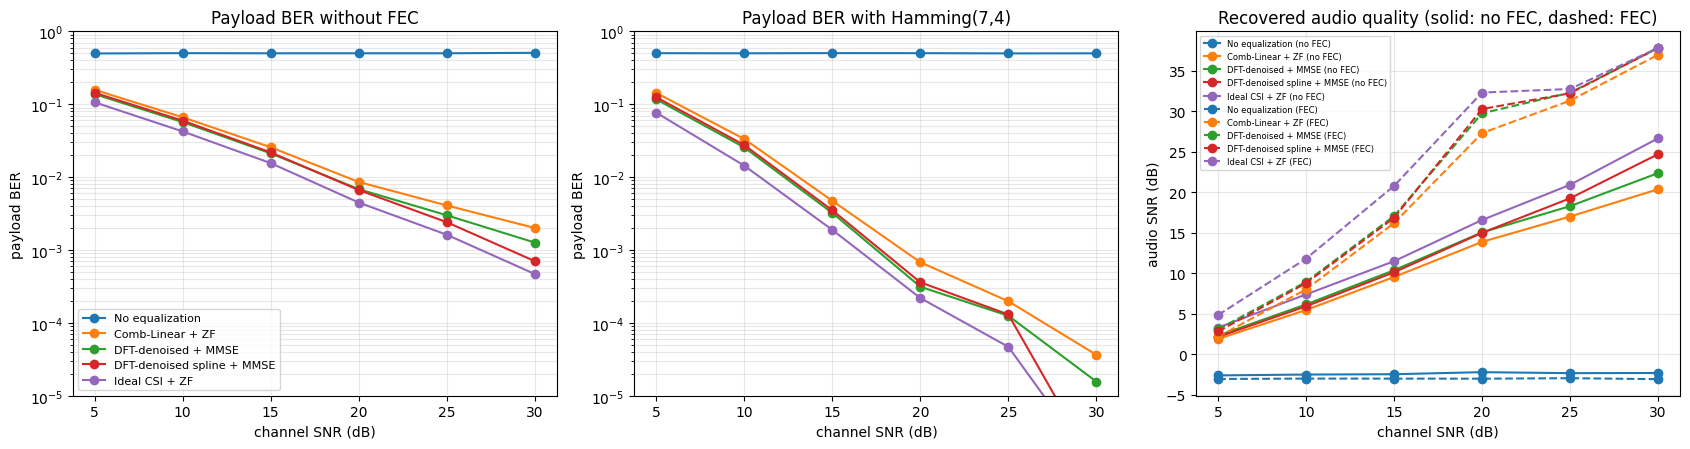

In [ ]:
snrs = [5, 10, 15, 20, 25, 30]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for use_fec, ls in [(False, '-'), (True, '--')]:
    ber_tab = {n: [] for n in SCHEMES}; snr_tab = {n: [] for n in SCHEMES}
    for s in snrs:
        r = transmit_audio(audio_bits, s, use_fec)
        for n, (rx, ber) in r.items():
            ber_tab[n].append(max(ber, 1e-6)); snr_tab[n].append(audio_snr_db(audio, bits_to_audio(rx)))
    k = 1 if use_fec else 0
    for i, n in enumerate(SCHEMES):
        ax[k].semilogy(snrs, ber_tab[n], 'o-', color=f'C{i}', label=n)
        ax[2].plot(snrs, snr_tab[n], 'o' + ls, color=f'C{i}', label=f"{n} ({'FEC' if use_fec else 'no FEC'})")
    ax[k].set(xlabel='channel SNR (dB)', ylabel='payload BER', ylim=(1e-5, 1),
              title='Payload BER ' + ('with Hamming(7,4)' if use_fec else 'without FEC'))
ax[2].set(xlabel='channel SNR (dB)', ylabel='audio SNR (dB)', title='Recovered audio quality (solid: no FEC, dashed: FEC)')
for a in ax: a.grid(True, which='both', alpha=0.3)
ax[0].legend(fontsize=8); ax[2].legend(fontsize=6)
plt.tight_layout(); plt.show()

## 15. Mobile Rayleigh channel: Doppler, BEM and banded MMSE

This extension uses time-varying Rayleigh taps and clustered pilots with guard nulls. It keeps the original `N`, `CP`, modem, delay filter and audio front end. `P_CLUSTERS` is adapted to `N` so that the clusters do not overlap or leave the FFT grid. The dense true-channel MMSE receiver is a simulation reference, not an implementable channel estimator.

In [ ]:
EPS = 0.2          # max Doppler in subcarrier spacings
Q = 2              # band half-width
P_CLUSTERS = min(16, N // (4 * Q + 8))
PILOT_AMP = 2.0
assert P_CLUSTERS >= L_taps, "Need at least L_taps non-overlapping pilot clusters."
assert Q >= int(np.ceil(EPS)) + 1


In [ ]:
def generate_channel_doppler(n_symbols, eps, M=32, chunk=64):
    """Taps h[s, l, n] over the whole symbol (CP + N samples). Sum-of-sinusoids,
    max Doppler = eps subcarrier spacings. Independent realisation per OFDM symbol."""
    T = N + CP
    n = np.arange(T)
    h = np.empty((n_symbols, L_taps, T), dtype=complex)
    for s0 in range(0, n_symbols, chunk):
        S = min(chunk, n_symbols - s0)
        theta = rng.uniform(0, 2*np.pi, (S, L_taps, M, 1))
        phi   = rng.uniform(0, 2*np.pi, (S, L_taps, M, 1))
        ph = 2*np.pi*eps*np.cos(theta)*n/N + phi            # (S, L, M, T)
        h[s0:s0+S] = np.exp(1j*ph).sum(axis=2) / np.sqrt(M)
    return h * np.sqrt(tap_powers)[None, :, None]


def apply_channel_tv(x, h):
    """y[n] = sum_l h_l[n] x[n-l], time-varying taps, all symbols at once."""
    y = np.zeros_like(x)
    for l in range(L_taps):
        y[:, l:] += h[:, l, l:] * x[:, :x.shape[1] - l]
    return y


def true_Hf_batch(h):
    """Genie N x N frequency-domain channel matrices, shape (S, N, N)."""
    S = h.shape[0]
    Hc = np.zeros((S, N, N), dtype=complex)
    n = np.arange(N)
    for l in range(L_taps):
        Hc[:, n, (n - l) % N] = h[:, l, CP:CP + N]
    return np.fft.ifft(np.fft.fft(Hc, axis=1, norm="ortho"), axis=2, norm="ortho")   # F Hc F^H

In [ ]:
# ---- frame layout: pilot clusters + guard nulls ----
CENTERS = ((np.arange(P_CLUSTERS) + 0.5) * N / P_CLUSTERS).astype(int)
NULL_BINS = np.unique(np.concatenate([CENTERS + j for j in range(-2*Q, 2*Q + 1)]))
DATA_IDX_MOB = np.setdiff1d(np.arange(N), NULL_BINS)
BITS_PER_OFDM_MOB = len(DATA_IDX_MOB) * modem.bps
print(f"mobile frame: {len(DATA_IDX_MOB)} data bins/symbol -> {BITS_PER_OFDM_MOB} payload bits "
      f"(static frame: {BITS_PER_OFDM})")


def make_link_mobile(bits, eps=None):
    eps = EPS if eps is None else eps
    bits = np.asarray(bits, dtype=np.int8).ravel()
    n_symbols = int(np.ceil(bits.size / BITS_PER_OFDM_MOB))
    padded = np.zeros(n_symbols * BITS_PER_OFDM_MOB, dtype=np.int8)
    padded[:bits.size] = bits
    X = np.zeros((n_symbols, N), dtype=complex)
    X[:, DATA_IDX_MOB] = modem.mod(padded).reshape(n_symbols, -1)
    X[:, CENTERS] = PILOT_AMP * PILOT_VAL
    h = generate_channel_doppler(n_symbols, eps)
    return dict(bits=padded, n_payload=bits.size, X=X, h=h,
                y_clean=apply_channel_tv(ofdm_tx(X), h))      # receive(link, snr) works unchanged


# ---- CE-BEM estimation (batched). D[:, qi, m] = Hf[m+q, m], q = -Q..Q ----
_A = np.exp(-2j*np.pi*np.outer(CENTERS, np.arange(L_taps)) / N)
_Apinv = np.linalg.pinv(_A)
_Fl = np.exp(-2j*np.pi*np.outer(np.arange(N), np.arange(L_taps)) / N)

def bem_estimate_batch(Y):
    D = np.zeros((Y.shape[0], 2*Q + 1, N), dtype=complex)
    for qi, q in enumerate(range(-Q, Q + 1)):
        d = Y[:, (CENTERS + q) % N] / (PILOT_AMP * PILOT_VAL)     # (S, P)
        D[:, qi] = (d @ _Apinv.T) @ _Fl.T                         # LS-fit L taps, back to N bins
    return D

def band_from_D_batch(D):
    Hb = D.copy()
    m = np.arange(N)
    for qi, q in enumerate(range(-Q, Q + 1)):
        Hb[:, qi, (m + q < 0) | (m + q >= N)] = 0
    return Hb

def dense_from_band(Hb):                       # single symbol, for validation only
    Hd = np.zeros((N, N), dtype=complex); m = np.arange(N)
    for qi, q in enumerate(range(-Q, Q + 1)):
        ok = (m + q >= 0) & (m + q < N)
        Hd[m[ok] + q, m[ok]] = Hb[qi, ok]
    return Hd


# ---- banded LDL^H MMSE, vectorised over symbols (loop only over subcarriers) ----
def mmse_banded_ldl_batch(Hb, Y, sigma2):
    S = Y.shape[0]; w = 2*Q
    Aup = np.zeros((S, w + 1, N), dtype=complex)
    for d in range(w + 1):
        acc = np.zeros((S, N - d), dtype=complex)
        for p in range(d - Q, Q + 1):
            acc += np.conj(Hb[:, p + Q, :N - d]) * Hb[:, p - d + Q, d:]
        Aup[:, d, :N - d] = acc
    Aup[:, 0, :] += sigma2

    ypad = np.concatenate([np.zeros((S, Q)), Y, np.zeros((S, Q))], axis=1)
    b = np.zeros((S, N), dtype=complex)
    for p in range(-Q, Q + 1):
        b += np.conj(Hb[:, p + Q]) * ypad[:, Q + p: Q + p + N]

    Lb = np.zeros((S, N, w + 1), dtype=complex)
    dg = np.zeros((S, N))
    for j in range(N):
        s = Aup[:, 0, j].real.copy()
        for t in range(1, min(w, j) + 1):
            s -= np.abs(Lb[:, j, t])**2 * dg[:, j - t]
        dg[:, j] = s
        for i in range(j + 1, min(N, j + w + 1)):
            v = np.conj(Aup[:, i - j, j])
            for k in range(max(0, i - w), j):
                v = v - Lb[:, i, i - k] * dg[:, k] * np.conj(Lb[:, j, j - k])
            Lb[:, i, i - j] = v / dg[:, j]

    z = b.copy()
    for i in range(N):
        for t in range(1, min(w, i) + 1):
            z[:, i] -= Lb[:, i, t] * z[:, i - t]
    x = z / dg
    for i in range(N - 1, -1, -1):
        for t in range(1, min(w, N - 1 - i) + 1):
            x[:, i] -= np.conj(Lb[:, i + t, t]) * x[:, i + t]
    return x


def genie_mmse(h, Y, sigma2, chunk=32):
    """Dense MMSE with the TRUE Hf (reference only, O(N^3) per symbol)."""
    out = np.empty_like(Y)
    for s0 in range(0, Y.shape[0], chunk):
        sl = slice(s0, s0 + chunk)
        H = true_Hf_batch(h[sl])
        Hh = np.conj(H.transpose(0, 2, 1))
        out[sl] = np.linalg.solve(Hh @ H + sigma2*np.eye(N), Hh @ Y[sl][..., None])[..., 0]
    return out


# ---- quick correctness check: batched banded == dense MMSE on the same banded H ----
_bits = rng.integers(0, 2, 5 * BITS_PER_OFDM_MOB)
_lk = make_link_mobile(_bits); _Y = receive(_lk, 30)
_Hb = band_from_D_batch(bem_estimate_batch(_Y)); _s2 = 1e-3
_xb = mmse_banded_ldl_batch(_Hb, _Y, _s2)
for s in range(3):
    Hd = dense_from_band(_Hb[s])
    xd = np.linalg.solve(Hd.conj().T @ Hd + _s2*np.eye(N), Hd.conj().T @ _Y[s])
    assert np.max(np.abs(xd - _xb[s])) < 1e-8
print("batched banded LDL^H matches dense MMSE")

mobile frame: 28 data bins/symbol -> 56 payload bits (static frame: 94)
batched banded LDL^H matches dense MMSE


In [ ]:
def ls_cluster_interp(Y):
    """'Static-style' estimate from the cluster pilots only (ignores ICI)."""
    Hp = Y[:, CENTERS] / (PILOT_AMP * PILOT_VAL)
    return interp1d(CENTERS, Hp, kind='linear', axis=1,
                    bounds_error=False, fill_value='extrapolate')(SUBCARRIERS)


def mobile_receive_all(link, Y, snr_db, genie=True):
    s2 = 10 ** (-snr_db / 10)
    D = bem_estimate_batch(Y)
    Hb = band_from_D_batch(D)
    Hs = delay_filter(ls_cluster_interp(Y))[:, DATA_IDX_MOB]
    Yd = Y[:, DATA_IDX_MOB]
    out = {
        "No equalization":                      Yd,
        "Static pipeline (LS+delay filt, 1-tap MMSE)": np.conj(Hs) * Yd / (np.abs(Hs)**2 + s2),
        "BEM diag + 1-tap ZF":                  (Y / D[:, Q])[:, DATA_IDX_MOB],
        "BEM + banded LDL^H":                   mmse_banded_ldl_batch(Hb, Y, s2)[:, DATA_IDX_MOB],
    }
    if genie:
        out["Genie full MMSE (true Hf)"] = genie_mmse(link['h'], Y, s2)[:, DATA_IDX_MOB]
    return out


def transmit_audio_mobile(bits, snr_db, use_fec=False, eps=None, genie=True):
    tx = bits
    if use_fec:
        coded = hamming_encode(bits)
        perm = make_interleaver(coded.size)
        tx = coded[perm]
    link = make_link_mobile(tx, eps)
    Y = receive(link, snr_db)
    out = {}
    for name, xeq in mobile_receive_all(link, Y, snr_db, genie).items():
        rx = modem.demod(xeq)[:link['n_payload']]
        if use_fec:
            deint = np.empty_like(rx); deint[perm] = rx
            rx = hamming_decode(deint)
        out[name] = (rx, np.mean(rx != bits))
    return out

## 16. Run and listen to the mobile audio demo

These results use the Doppler channel. The static delay-filter receiver is included as a comparison under time variation. The full true-channel MMSE reference costs more computation; pass `genie=False` to `transmit_audio_mobile` to omit it.

In [ ]:
DEMO_SNR = 30
DEMO_EPS = 0.2
USE_FEC = False

res = transmit_audio_mobile(audio_bits, DEMO_SNR, USE_FEC, eps=DEMO_EPS)

decoded = {}
print(f"{modulation_type}, SNR={DEMO_SNR} dB, eps={DEMO_EPS}, FEC={USE_FEC}")
print(f"{'scheme':48s} {'BER':>9s} {'audio SNR (dB)':>15s}")
for i, (name, (rx_bits, ber)) in enumerate(res.items(), start=2):
    y = bits_to_audio(rx_bits)
    decoded[name] = y
    print(f"{name:48s} {ber:9.5f} {audio_snr_db(audio, y):15.1f}")
    fn = name.replace(' ', '_').replace('+', 'plus').replace('(', '').replace(')', '').replace(',', '').replace('^', '').replace('/', '')
    wavfile.write(f"{OUT_DIR}/mobile_{i}_{fn}.wav", FS, (np.clip(y, -1, 1) * 32767).astype(np.int16))

QPSK, SNR=30 dB, eps=0.2, FEC=False
scheme                                                 BER  audio SNR (dB)
No equalization                                    0.49476            -2.4
Static pipeline (LS+delay filt, 1-tap MMSE)        0.09902             4.0
BEM diag + 1-tap ZF                                0.02387             8.9
BEM + banded LDL^H                                 0.01341            11.7
Genie full MMSE (true Hf)                          0.00057            25.6


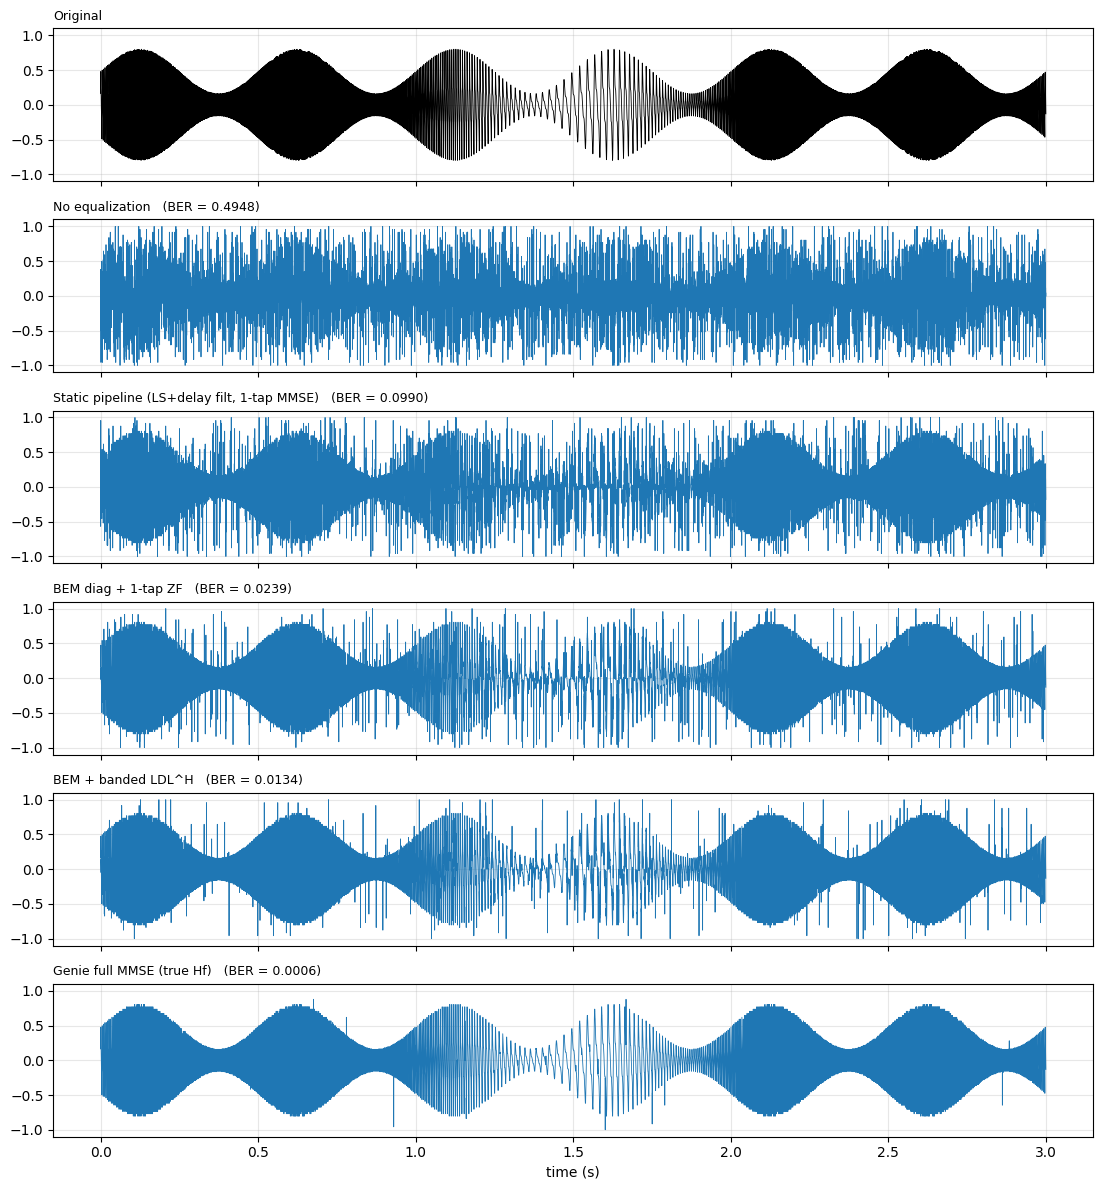

In [ ]:
fig, ax = plt.subplots(len(decoded) + 1, 1, figsize=(11, 2 * (len(decoded) + 1)), sharex=True, sharey=True)
t = np.arange(audio.size) / FS
ax[0].plot(t, audio, color='k', lw=0.6); ax[0].set_title("Original", fontsize=9, loc='left')
for a, (name, y) in zip(ax[1:], decoded.items()):
    a.plot(t[:y.size], y, lw=0.6); a.set_title(f"{name}   (BER = {res[name][1]:.4f})", fontsize=9, loc='left')
for a in ax: a.grid(alpha=0.3)
ax[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

In [ ]:
print("Original");                      display(Audio(audio, rate=FS))
print("Error-free mu-law (best possible with 8-bit)"); display(Audio(audio_ref, rate=FS))
for name, y in decoded.items():
    print(name);                       display(Audio(np.clip(y, -1, 1), rate=FS))

Original


Error-free mu-law (best possible with 8-bit)


No equalization


Static pipeline (LS+delay filt, 1-tap MMSE)


BEM diag + 1-tap ZF


BEM + banded LDL^H


Genie full MMSE (true Hf)


## 17. Mobile BER versus SNR and Doppler

The sweeps use up to one second of audio. Each point creates a new random channel and noise realization; receiver schemes within a point share the received signal. Zero measured BER is plotted at `1e-6` for visibility on the logarithmic axis.

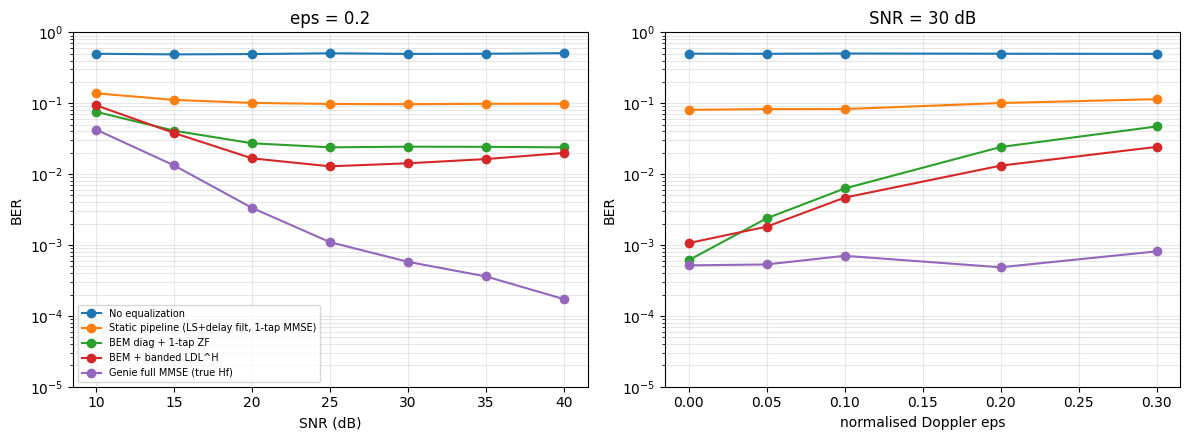

In [ ]:
short = audio_bits[:8 * FS]       # 1 second

# (a) BER vs SNR at fixed Doppler
snrs = [10, 15, 20, 25, 30, 35, 40]
tab = {}
for s in snrs:
    for n, (rx, ber) in transmit_audio_mobile(short, s, eps=0.2).items():
        tab.setdefault(n, []).append(max(ber, 1e-6))

# (b) BER vs Doppler at fixed SNR
epss = [0.0, 0.05, 0.1, 0.2, 0.3]
tab2 = {}
for e in epss:
    for n, (rx, ber) in transmit_audio_mobile(short, 30, eps=e).items():
        tab2.setdefault(n, []).append(max(ber, 1e-6))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, v in tab.items():  ax[0].semilogy(snrs, v, 'o-', label=n)
for n, v in tab2.items(): ax[1].semilogy(epss, v, 'o-', label=n)
ax[0].set(xlabel='SNR (dB)', ylabel='BER', title='eps = 0.2', ylim=(1e-5, 1))
ax[1].set(xlabel='normalised Doppler eps', ylabel='BER', title='SNR = 30 dB', ylim=(1e-5, 1))
for a in ax: a.grid(True, which='both', alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## Notes for the combined demo

* Channel estimation and equalization are the receiver correction stage; Hamming(7,4) with interleaving is an optional additional layer.
* Sections 10–14 use the original block-fading Rayleigh channel; Sections 15–17 use the time-varying Doppler extension.
* Audio SNR is measured against the original waveform, so it includes both transmission errors and mu-law quantization distortion. The error-free mu-law playback provides the codec reference.
* With QPSK and hard sign decisions, one-tap ZF and MMSE using the same channel estimate produce the same bit decisions. The displayed static schemes also differ in channel estimation.
* Keep `WAV_PATH` at a missing file to run with the synthetic fallback, or supply a local WAV path for speech/music. `MAX_SECONDS` controls workload.
